# Predicción de temperatura en Bogota
Serie temporal multivariada: con las últimas 48 horas se predice la temperatura de la **próxima hora**.

**Dataset:** Open-Meteo Historical API (Bogotá, 2019-2025, datos horarios).

In [ ]:
import os, json, joblib, requests
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
from numpy.lib.stride_tricks import sliding_window_view
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)
for d in ["data", "models", "reports"]:
    os.makedirs(d, exist_ok=True)

## 1. Dataset

In [ ]:
RAW = ["temperature_2m", "relative_humidity_2m", "dew_point_2m", "surface_pressure",
       "wind_speed_10m", "precipitation", "cloud_cover"]
WINDOW = 48

r = requests.get("https://archive-api.open-meteo.com/v1/archive", params={
    "latitude": 4.61, "longitude": -74.08, "start_date": "2019-01-01", "end_date": "2025-12-31",
    "hourly": ",".join(RAW), "timezone": "America/Bogota"}, timeout=120)
r.raise_for_status()
df = pd.DataFrame(r.json()["hourly"])
df.to_csv("data/bogota_hourly.csv", index=False)
print(df.shape)
df.head()

(61368, 8)


,time,temperature_2m,relative_humidity_2m,dew_point_2m,surface_pressure,wind_speed_10m,precipitation,cloud_cover
0,2019-01-01T00:00,10.4,92,9.1,752.7,9.3,0.1,79
1,2019-01-01T01:00,10.4,93,9.3,752.0,10.4,0.1,97
2,2019-01-01T02:00,10.5,94,9.5,751.6,11.5,0.0,96
3,2019-01-01T03:00,10.5,92,9.3,751.1,12.8,0.0,89
4,2019-01-01T04:00,10.1,91,8.7,751.0,12.8,0.0,78


## 2. Análisis exploratorio

In [ ]:
df["time"] = pd.to_datetime(df["time"])
print(df.info())
print("Nulos:\n", df.isna().sum())
print("Duplicados de fecha:", df["time"].duplicated().sum())
df.describe().T

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 61368 entries, 0 to 61367
Data columns (total 8 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   time                  61368 non-null  datetime64[ns]
 1   temperature_2m        61368 non-null  float64       
 2   relative_humidity_2m  61368 non-null  int64         
 3   dew_point_2m          61368 non-null  float64       
 4   surface_pressure      61368 non-null  float64       
 5   wind_speed_10m        61368 non-null  float64       
 6   precipitation         61368 non-null  float64       
 7   cloud_cover           61368 non-null  int64         
dtypes: datetime64[ns](1), float64(5), int64(2)
memory usage: 3.7 MB
None
Nulos:
 time                    0
temperature_2m          0
relative_humidity_2m    0
dew_point_2m            0
surface_pressure        0
wind_speed_10m          0
precipitation           0
cloud_cover             0
dtype: int64
Duplicado

,count,mean,min,25%,50%,75%,max,std
time,61368,2022-07-02 11:30:00,2019-01-01 00:00:00,2020-10-01 05:45:00,2022-07-02 11:30:00,2024-04-01 17:15:00,2025-12-31 23:00:00,NaN
temperature_2m,61368.0,13.217201,2.6,10.8,12.6,15.7,24.9,3.079801
relative_humidity_2m,61368.0,82.358444,20.0,71.0,87.0,95.0,100.0,15.189026
dew_point_2m,61368.0,9.95643,-5.5,9.1,10.1,11.0,15.7,1.549455
surface_pressure,61368.0,754.6497,744.5,753.2,754.5,756.1,761.5,2.093871
wind_speed_10m,61368.0,9.239969,0.0,5.3,8.1,13.0,28.4,5.203339
precipitation,61368.0,0.100772,0.0,0.0,0.0,0.1,8.8,0.358708
cloud_cover,61368.0,85.185895,0.0,78.0,97.0,100.0,100.0,22.498889


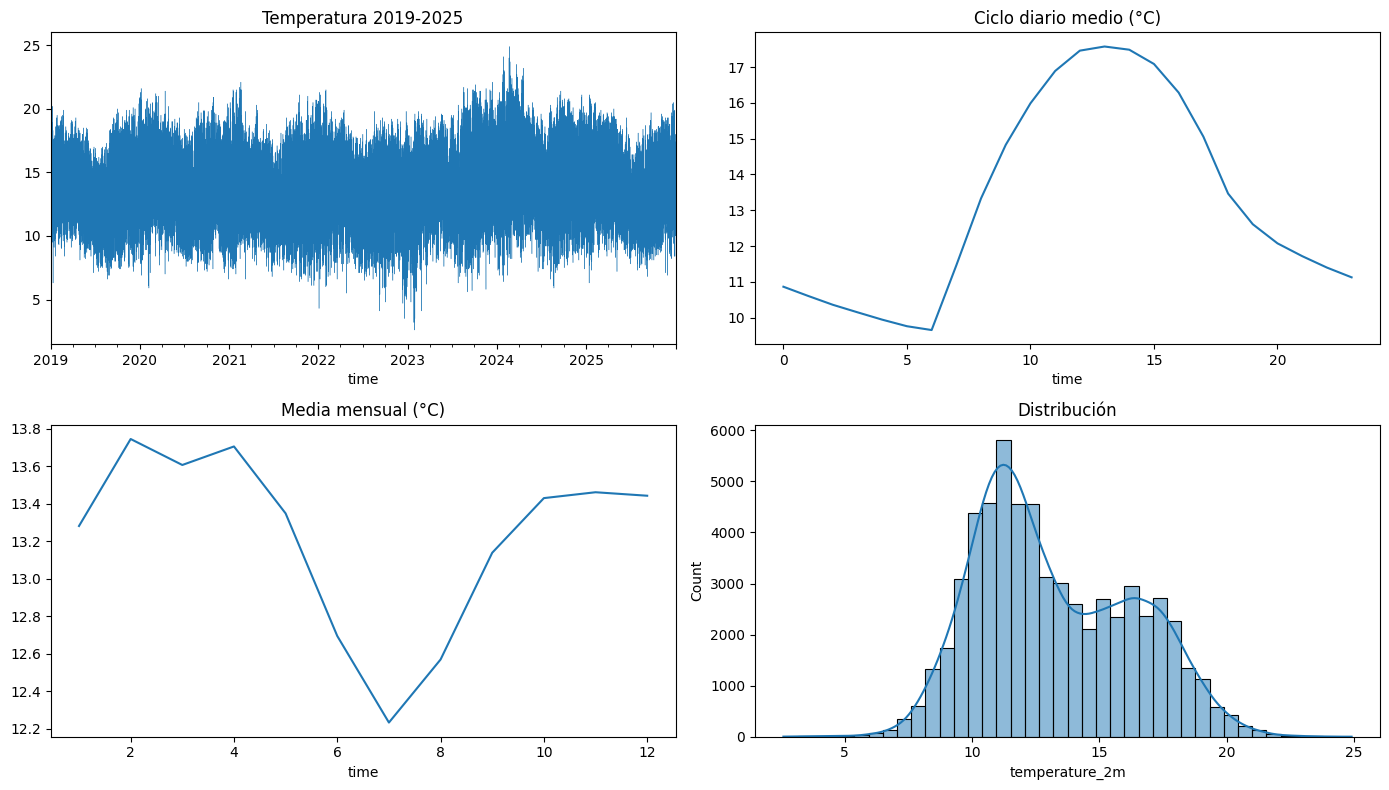

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(14, 8))
df.set_index("time")["temperature_2m"].plot(ax=ax[0, 0], lw=0.3, title="Temperatura 2019-2025")
df.groupby(df["time"].dt.hour)["temperature_2m"].mean().plot(ax=ax[0, 1], title="Ciclo diario medio (°C)")
df.groupby(df["time"].dt.month)["temperature_2m"].mean().plot(ax=ax[1, 0], title="Media mensual (°C)")
sns.histplot(df["temperature_2m"], bins=40, kde=True, ax=ax[1, 1]); ax[1, 1].set_title("Distribución")
plt.tight_layout(); plt.show()

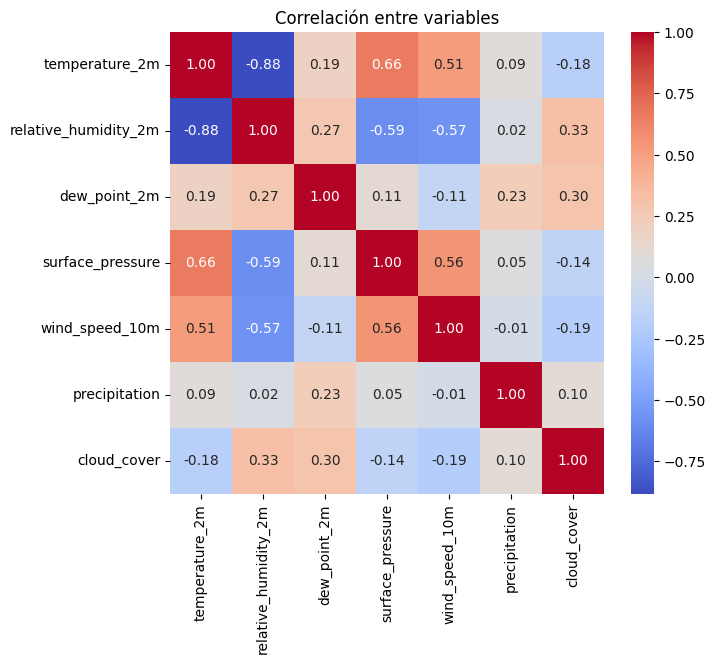

In [ ]:
plt.figure(figsize=(7, 6))
sns.heatmap(df[RAW].corr(), annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlación entre variables"); plt.show()

## 3. Limpieza y preprocesamiento
- Orden por fecha, eliminación de duplicados e interpolación de nulos.
- Variables cíclicas de la hora (seno y coseno).
- División **cronológica** 70/15/15 y escalado ajustado solo con entrenamiento.
- Ventanas deslizantes de 48 horas.

In [ ]:
df = df.sort_values("time").drop_duplicates("time").reset_index(drop=True)
df[RAW] = df[RAW].interpolate(limit_direction="both")
df["hour_sin"] = np.sin(2 * np.pi * df["time"].dt.hour / 24)
df["hour_cos"] = np.cos(2 * np.pi * df["time"].dt.hour / 24)
FEATURES = RAW + ["hour_sin", "hour_cos"]

n = len(df); a, b = int(n * 0.70), int(n * 0.85)
scaler = StandardScaler().fit(df.loc[:a - 1, FEATURES])
arr = scaler.transform(df[FEATURES]).astype("float32")
mu, sd = scaler.mean_[0], scaler.scale_[0]
inv = lambda v: v * sd + mu

def make_windows(x, window=WINDOW):
    X = sliding_window_view(x[:-1], (window, x.shape[1]))[:, 0]
    return X.astype("float32"), x[window:, 0].astype("float32")

Xtr, ytr = make_windows(arr[:a]); Xva, yva = make_windows(arr[a:b]); Xte, yte = make_windows(arr[b:])
print("train", Xtr.shape, "| val", Xva.shape, "| test", Xte.shape)

train (42909, 48, 9) | val (9157, 48, 9) | test (9158, 48, 9)


## 4. Modelos (GRU y LSTM) y baseline

In [ ]:
def build_model(kind):
    rnn = layers.GRU if kind == "gru" else layers.LSTM
    m = keras.Sequential([
        layers.Input((WINDOW, len(FEATURES))),
        rnn(64, return_sequences=True), layers.Dropout(0.2),
        rnn(32), layers.Dropout(0.2),
        layers.Dense(16, activation="relu"), layers.Dense(1)], name=kind)
    m.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse", metrics=["mae"])
    return m

build_model("gru").summary()

Model: "gru"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ gru (GRU)                       │ (None, 48, 64)         │        14,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 48, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ gru_1 (GRU)                     │ (None, 32)             │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,353 (95.13 KB)

 Trainable params: 24,353 (95.13 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
histories, preds, models = {}, {}, {}
for kind in ["gru", "lstm"]:
    m = build_model(kind)
    h = m.fit(Xtr, ytr, validation_data=(Xva, yva), epochs=30, batch_size=128, verbose=2,
              callbacks=[keras.callbacks.EarlyStopping(patience=5, restore_best_weights=True),
                         keras.callbacks.ReduceLROnPlateau(patience=2, factor=0.5)])
    histories[kind], models[kind] = h.history, m
    preds[kind] = inv(m.predict(Xte, verbose=0).ravel())

Epoch 1/30
336/336 - 51s - 152ms/step - loss: 0.1028 - mae: 0.2354 - val_loss: 0.0702 - val_mae: 0.1998 - learning_rate: 0.0010
Epoch 2/30
336/336 - 42s - 126ms/step - loss: 0.0581 - mae: 0.1836 - val_loss: 0.0505 - val_mae: 0.1692 - learning_rate: 0.0010
Epoch 3/30
336/336 - 80s - 237ms/step - loss: 0.0509 - mae: 0.1711 - val_loss: 0.0428 - val_mae: 0.1555 - learning_rate: 0.0010
Epoch 4/30
336/336 - 40s - 119ms/step - loss: 0.0468 - mae: 0.1642 - val_loss: 0.0422 - val_mae: 0.1536 - learning_rate: 0.0010
Epoch 5/30
336/336 - 40s - 120ms/step - loss: 0.0436 - mae: 0.1580 - val_loss: 0.0407 - val_mae: 0.1514 - learning_rate: 0.0010
Epoch 6/30
336/336 - 43s - 129ms/step - loss: 0.0411 - mae: 0.1540 - val_loss: 0.0367 - val_mae: 0.1424 - learning_rate: 0.0010
Epoch 7/30
336/336 - 55s - 163ms/step - loss: 0.0400 - mae: 0.1520 - val_loss: 0.0407 - val_mae: 0.1520 - learning_rate: 0.0010
Epoch 8/30
336/336 - 69s - 205ms/step - loss: 0.0389 - mae: 0.1493 - val_loss: 0.0382 - val_mae: 0.1464 

## 5. Gráficas del entrenamiento

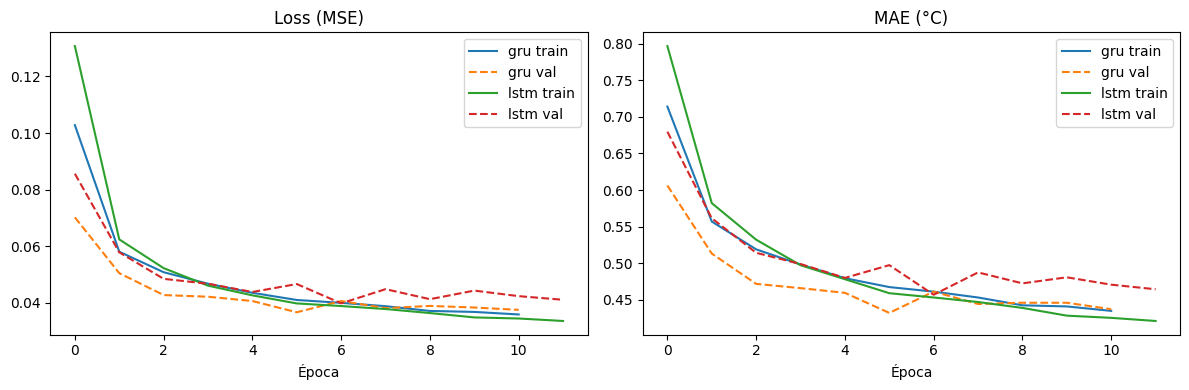

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for k, h in histories.items():
    ax[0].plot(h["loss"], label=f"{k} train"); ax[0].plot(h["val_loss"], "--", label=f"{k} val")
    ax[1].plot(np.array(h["mae"]) * sd, label=f"{k} train"); ax[1].plot(np.array(h["val_mae"]) * sd, "--", label=f"{k} val")
ax[0].set(title="Loss (MSE)", xlabel="Época"); ax[1].set(title="MAE (°C)", xlabel="Época")
ax[0].legend(); ax[1].legend(); plt.tight_layout()
plt.savefig("reports/training_curves.png", dpi=120); plt.show()

## 6. Evaluación en el conjunto de prueba

In [ ]:
yte_c = inv(yte)
def metrics(y, p):
    return {"MAE": mean_absolute_error(y, p), "RMSE": float(np.sqrt(mean_squared_error(y, p))), "R2": r2_score(y, p)}

results = {"baseline": metrics(yte_c, inv(Xte[:, -1, 0])),
           "gru": metrics(yte_c, preds["gru"]), "lstm": metrics(yte_c, preds["lstm"])}
pd.DataFrame(results).T.round(3)

,MAE,RMSE,R2
baseline,0.750,1.005,0.879
gru,0.379,0.511,0.969
lstm,0.409,0.546,0.964


Mejor modelo: GRU


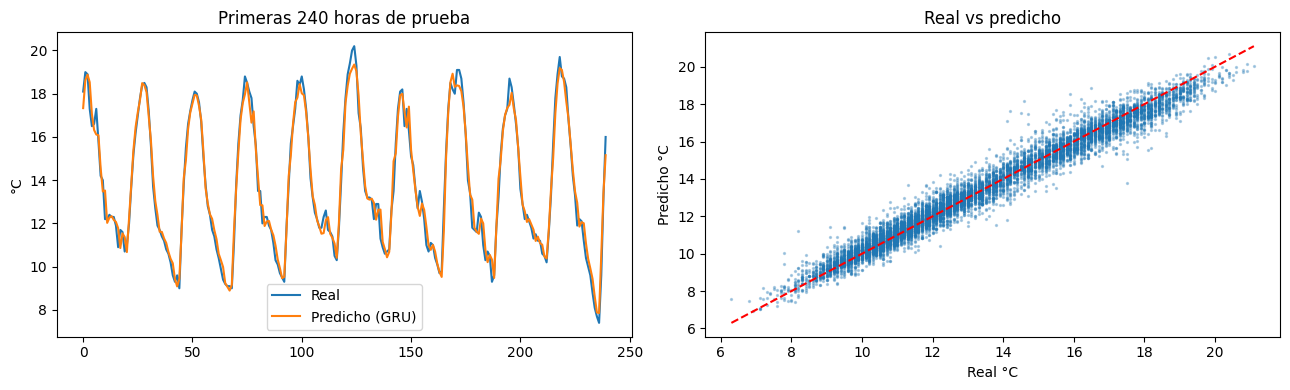

In [ ]:
best = min(["gru", "lstm"], key=lambda k: results[k]["MAE"]); p = preds[best]
print("Mejor modelo:", best.upper())
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
ax[0].plot(yte_c[:240], label="Real"); ax[0].plot(p[:240], label=f"Predicho ({best.upper()})")
ax[0].set(title="Primeras 240 horas de prueba", ylabel="°C"); ax[0].legend()
ax[1].scatter(yte_c, p, s=2, alpha=0.3); lim = [yte_c.min(), yte_c.max()]; ax[1].plot(lim, lim, "r--")
ax[1].set(title="Real vs predicho", xlabel="Real °C", ylabel="Predicho °C")
plt.tight_layout(); plt.savefig("reports/pred_vs_real.png", dpi=120); plt.show()

## 7. Diez predicciones de prueba

In [ ]:
idx = np.linspace(0, len(yte_c) - 1, 10).astype(int)
times = df["time"].iloc[b + WINDOW:].reset_index(drop=True)
tabla = pd.DataFrame({"hora_objetivo": times.iloc[idx].values, "real_C": yte_c[idx].round(2), "predicho_C": p[idx].round(2)})
tabla["error_C"] = (tabla.predicho_C - tabla.real_C).round(2)
tabla.to_csv("reports/predicciones_test.csv", index=False)
tabla

,hora_objetivo,real_C,predicho_C,error_C
0,2024-12-15 10:00:00,18.1,17.33,-0.77
1,2025-01-26 19:00:00,12.0,11.72,-0.28
2,2025-03-10 04:00:00,11.2,10.64,-0.56
3,2025-04-21 14:00:00,16.8,17.71,0.91
4,2025-06-02 23:00:00,10.7,10.63,-0.07
5,2025-07-15 09:00:00,11.3,12.44,1.14
6,2025-08-26 18:00:00,11.0,10.96,-0.04
7,2025-10-08 04:00:00,10.0,9.13,-0.87
8,2025-11-19 13:00:00,18.1,17.96,-0.14
9,2025-12-31 23:00:00,11.6,11.07,-0.53


## 8. Guardado del modelo

In [ ]:
models[best].save("models/modelo.keras")
joblib.dump(scaler, "models/scaler.pkl")
json.dump({"window": WINDOW, "features": FEATURES, "best_model": best, "test_start": int(b),
           "n_rows": int(n), "results": results}, open("models/config.json", "w"), indent=2)
json.dump(results, open("reports/metrics.json", "w"), indent=2)

loaded = keras.models.load_model("models/modelo.keras")
print("Verificación de carga:", np.allclose(loaded.predict(Xte[:5], verbose=0), models[best].predict(Xte[:5], verbose=0)))

Verificación de carga: True


In [15]:
from google.colab import files
files.download("models/modelo.keras")
files.download("models/scaler.pkl")
files.download("models/config.json")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 9. Paquete completo para el repositorio
Descarga un ZIP con los datos, modelo, scaler, configuraci?n y reportes generados.

In [ ]:
from zipfile import ZipFile, ZIP_DEFLATED
from google.colab import files
from pathlib import Path

bundle = "proyecto_rnn_clima_colab.zip"
with ZipFile(bundle, "w", ZIP_DEFLATED) as z:
    for folder in ["data", "models", "reports"]:
        for path in Path(folder).glob("*"):
            if path.is_file():
                z.write(path, path.as_posix())
files.download(bundle)
